# Multi-Key OpenWInD Whistle Design Pipeline

Dieses Notebook orchestriert die drei Stufen Bore/Oktave, Tonlochplatzierung und Undercutting für mehrere Whistle-Tonarten. Die schwere Modell- und Optimierungslogik liegt im Package `tin_whistle_openwind`.

In [37]:
from pathlib import Path
import importlib
import json
import numpy as np
import matplotlib.pyplot as plt

import tin_whistle_openwind.optimizer as optimizer_module
import tin_whistle_openwind.optimize_toneholes as tonehole_module
import tin_whistle_openwind.pipeline as pipeline_module
importlib.reload(optimizer_module)
importlib.reload(tonehole_module)
importlib.reload(pipeline_module)

from tin_whistle_openwind.keys import SUPPORTED_KEYS
from tin_whistle_openwind.tuning import (
    IRISH_FOLK_HYBRID, EQUAL_TEMPERAMENT, JUST_INTONATION,
    STANDARD_FINGERINGS, generate_key_frequencies,
)
from tin_whistle_openwind.pipeline import WhistleDesignPipeline
from tin_whistle_openwind.optimizer import fingering_chart_rows

TEMPERAMENTS = {
    'Irish_Folk_Hybrid': IRISH_FOLK_HYBRID,
    '12-TET': EQUAL_TEMPERAMENT,
    'Just_Intonation': JUST_INTONATION,
}
KEY_NAME = 'Soprano_D'
TEMPERAMENT_NAME = 'Irish_Folk_Hybrid'
print('Keys:', ', '.join(SUPPORTED_KEYS))

Keys: Soprano_D, Soprano_C, High_Bb, Alto_A, Low_D


## 1. Key- und Temperamentauswahl

Die Tonleiter wird aus der Grundfrequenz und Cent-Intervallen erzeugt. Der Irish Folk Hybrid ist der Default; 12-TET und Just Intonation können über `TEMPERAMENT_NAME` gewählt werden.

In [38]:
key_config = SUPPORTED_KEYS[KEY_NAME]
tuning = TEMPERAMENTS[TEMPERAMENT_NAME]
targets_hz = generate_key_frequencies(key_config, TEMPERAMENT_NAME)
print(key_config.name, '|', tuning.name)
for note, frequency in targets_hz.items():
    print(f'{note:20s} {frequency:8.2f} Hz')

print('D6 fingering:', STANDARD_FINGERINGS['Octave_Degree_1'])
print('Fork fingering:', STANDARD_FINGERINGS['Fork_Minor7'])

Soprano High D | Irish Folk Hybrid (HB-trad / Copeland standard)
Degree_1               587.33 Hz
Degree_2               660.02 Hz
Degree_3               736.58 Hz
Degree_4               783.99 Hz
Degree_5               880.00 Hz
Degree_6               983.21 Hz
Fork_Minor7           1042.88 Hz
Degree_7              1105.53 Hz
Octave_Degree_1       1174.66 Hz
D6 fingering: [0, 1, 1, 1, 1, 1]
Fork fingering: [0, 1, 1, 0, 0, 0]


## 2. Stage 1: Bore und Bell-Ende

Ein zylindrischer Ausgangsbore wird als reproduzierbarer Startpunkt erzeugt. Eine spätere Messdatenkalibrierung kann die Segmente durch einen Reverse-Taper ersetzen, um das Oktavverhältnis $f_2/f_1$ auf 2.000 zu bringen.

Bore: Soprano High D cylindrical bore | length: 263.6 mm


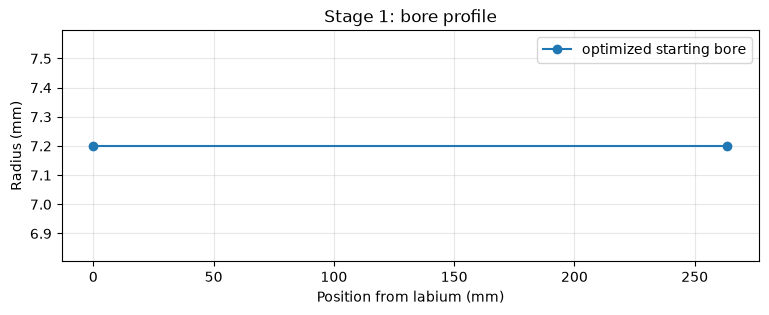

In [39]:
pipeline = WhistleDesignPipeline(KEY_NAME, tuning)
bore = pipeline.run_stage_1_bore_optimization()
print('Bore:', bore.name, '| length:', f'{bore.length_m * 1000:.1f} mm')

positions_mm = [position * 1000 for position, _ in bore.segments]
radii_mm = [radius * 1000 for _, radius in bore.segments]
plt.figure(figsize=(9, 3))
plt.plot(positions_mm, radii_mm, 'o-', label='optimized starting bore')
plt.xlabel('Position from labium (mm)')
plt.ylabel('Radius (mm)')
plt.title('Stage 1: bore profile')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 3. Stage 2: Tonlochplatzierung und Bohrplan

Die sechs Löcher werden mit mindestens 18 mm Abstand, 5-8 mm Durchmesser und mindestens 30 mm Abstand zum Rohrende optimiert. Fork-Fingerings und das vented D6 sind Teil der OpenWInD-Fingering-Chart.

In [40]:
holes = pipeline.run_stage_2_tonehole_optimization(bore)
rows = []
for index, hole in enumerate(holes.holes, start=1):
    previous = holes.holes[index - 2].position_m if index > 1 else None
    spacing = '' if previous is None else f'{(hole.position_m - previous) * 1000:.1f}'
    rows.append({
        'Hole name': hole.label,
        'Hole': index,
        'Position from labium (mm)': round(hole.position_m * 1000, 2),
        'Spacing (mm)': spacing,
        'Drill diameter (mm)': round(hole.diameter_m * 1000, 2),
    })
display(rows)
tonehole_result = pipeline.tonehole_result
print(fingering_chart_rows())
print(f'Optimizer status: {tonehole_result.result.message}')
print(f'Initial cost: {tonehole_result.initial_cost:.3f}')
print(f'Final cost:   {tonehole_result.final_cost:.3f}')
print(f'Improvement:  {tonehole_result.improvement:.3f} ({tonehole_result.improvement / max(abs(tonehole_result.initial_cost), 1e-12) * 100:.2f}%)')
print(f'Objective improved: {tonehole_result.improved}')
print('Cent errors:', {note: round(error, 2) for note, error in tonehole_result.cent_errors.items()})

[{'Hole name': 'L1',
  'Hole': 1,
  'Position from labium (mm)': np.float64(117.11),
  'Spacing (mm)': '',
  'Drill diameter (mm)': np.float64(5.5)},
 {'Hole name': 'L2',
  'Hole': 2,
  'Position from labium (mm)': np.float64(136.91),
  'Spacing (mm)': '19.8',
  'Drill diameter (mm)': np.float64(6.5)},
 {'Hole name': 'L3',
  'Hole': 3,
  'Position from labium (mm)': np.float64(156.01),
  'Spacing (mm)': '19.1',
  'Drill diameter (mm)': np.float64(6.0)},
 {'Hole name': 'R1',
  'Hole': 4,
  'Position from labium (mm)': np.float64(179.11),
  'Spacing (mm)': '23.1',
  'Drill diameter (mm)': np.float64(5.0)},
 {'Hole name': 'R2',
  'Hole': 5,
  'Position from labium (mm)': np.float64(197.61),
  'Spacing (mm)': '18.5',
  'Drill diameter (mm)': np.float64(8.0)},
 {'Hole name': 'R3',
  'Hole': 6,
  'Position from labium (mm)': np.float64(224.51),
  'Spacing (mm)': '26.9',
  'Drill diameter (mm)': np.float64(8.0)}]

[['label', 'Degree_1', 'Degree_2', 'Degree_3', 'Degree_4', 'Degree_5', 'Degree_6', 'Fork_Minor7', 'Degree_7', 'Octave_Degree_1'], ['L1', 'x', 'x', 'x', 'x', 'x', 'x', 'o', 'o', 'o'], ['L2', 'x', 'x', 'x', 'x', 'x', 'o', 'x', 'o', 'x'], ['L3', 'x', 'x', 'x', 'x', 'o', 'o', 'x', 'o', 'x'], ['R1', 'x', 'x', 'x', 'o', 'o', 'o', 'o', 'o', 'x'], ['R2', 'x', 'x', 'o', 'o', 'o', 'o', 'o', 'o', 'x'], ['R3', 'x', 'o', 'o', 'o', 'o', 'o', 'o', 'o', 'x']]
Optimizer status: Optimization terminated successfully
Initial cost: 186161.492
Final cost:   186161.492
Improvement:  0.000 (0.00%)
Objective improved: False
Cent errors: {'Degree_1': np.float64(125.25), 'Degree_2': np.float64(114.3), 'Degree_3': np.float64(132.14), 'Degree_4': np.float64(137.09), 'Degree_5': np.float64(147.18), 'Degree_6': np.float64(177.32), 'Fork_Minor7': np.float64(80.35), 'Degree_7': np.float64(175.3), 'Octave_Degree_1': np.float64(175.68)}


## 3b. Messdatenbasierte OpenWInD-Inversion

Die eigentliche Optimierung verwendet keine synthetisch erzeugten Zielimpedanzen. Übergib hier gemessene, durch die Eingangs-Charakteristikimpedanz normalisierte komplexe Impedanzen pro Fingering. OpenWInD berechnet daraus Kosten, Sensitivitäten und die SLSQP-Schritte. `LTh` bleibt deaktiviert; optimiert werden nur `L1`, `L2`, `L3`, `R1`, `R2`, `R3`.

In [41]:
from tin_whistle_openwind.optimizer import InverseToneholeOptimizer

# Keine synthetischen Ziele erzeugen: diese Variablen müssen aus Messdaten geladen werden.
if 'measured_frequencies_hz' not in globals() or 'measured_impedances_normalized' not in globals():
    print('Messdaten fehlen: lade measured_frequencies_hz und measured_impedances_normalized, um OpenWInD-Inversion zu starten.')
else:
    inverse_optimizer = InverseToneholeOptimizer(bore, holes)
    inverse_result = inverse_optimizer.fit(
        measured_frequencies_hz,
        measured_impedances_normalized,
        notes=list(targets_hz),
        algorithm='SLSQP',
    )
    print(f'OpenWInD inverse status: {inverse_result.result.message}')
    print(f'Initial cost: {inverse_result.initial_cost:.6g}')
    print(f'Final cost: {inverse_result.final_cost:.6g}')
    print(f'Improved: {inverse_result.improved}')

Messdaten fehlen: lade measured_frequencies_hz und measured_impedances_normalized, um OpenWInD-Inversion zu starten.


## 4. Stage 3: Undercutting und Chimney-Bevel

Der innere Bevel wird zwischen 0 und 15 Grad gehalten. Die Außenpositionen bleiben unverändert; nur die effektive Chimney-Geometrie wird für die zweite Oktave verfeinert.

In [42]:
design = pipeline.run_stage_3_undercut_optimization(bore, holes)
print([(hole.label, hole.bevel_deg) for hole in design.holes.holes])

[('L1', 0.0), ('L2', 0.0), ('L3', 0.0), ('R1', 0.0), ('R2', 0.0), ('R3', 0.0)]


## 5. Admittanzspektren

Für Flöten werden Spielresonanzen als Peaks von $Y=1/|Z|$ gesucht. Die folgende Darstellung zeigt die Ziel-Frequenzen aller Scale Degrees; die eigentliche OpenWInD-Spektrumsberechnung kann über `OpenWInDToneholeModel.response()` je Fingering erfolgen.

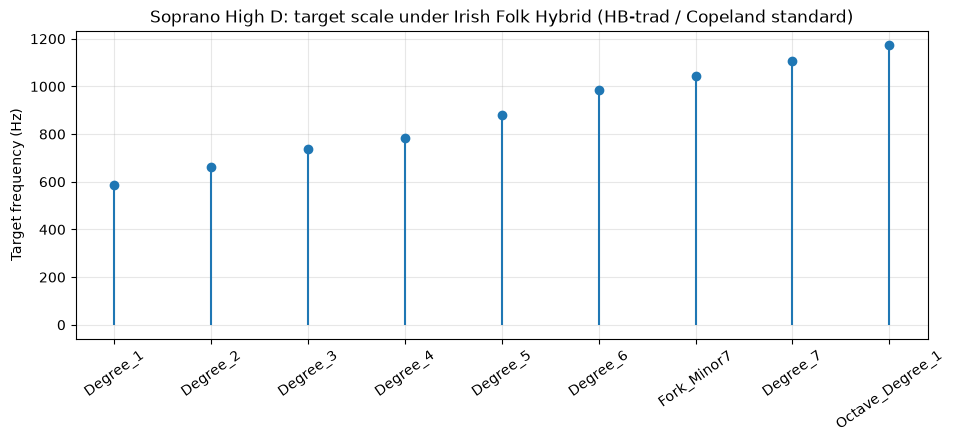

In [43]:
plt.figure(figsize=(11, 4))
plt.stem(list(targets_hz), list(targets_hz.values()), basefmt=' ')
plt.ylabel('Target frequency (Hz)')
plt.title(f'{key_config.name}: target scale under {tuning.name}')
plt.xticks(rotation=35)
plt.grid(alpha=0.3)
plt.show()

## 6. CAD-Export

Die vollständige dreistufige Konstruktion und ein kompakter Bohrplan werden als JSON/CSV exportiert.

In [44]:
output_dir = Path('../data')
output_dir.mkdir(parents=True, exist_ok=True)
design_path = output_dir / f'whistle_design_{KEY_NAME}_{TEMPERAMENT_NAME}.json'
design_path.write_text(json.dumps(design.to_dict(), indent=2), encoding='utf-8')
drill_path = output_dir / f'drilling_chart_{KEY_NAME}.csv'
drill_path.write_text('Hole,Position_mm,Spacing_mm,Drill_Diameter_mm\n' + '\n'.join(
    f"{row['Hole']},{row['Position from labium (mm)']},{row['Spacing (mm)']},{row['Drill diameter (mm)']}" for row in rows
), encoding='utf-8')
print(design_path.resolve())
print(drill_path.resolve())

C:\projects\p\openWind\data\whistle_design_Soprano_D_Irish_Folk_Hybrid.json
C:\projects\p\openWind\data\drilling_chart_Soprano_D.csv
